In [1]:
!pip -q install sentence-transformers scikit-learn


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.text import TfidfVectorizer


In [3]:
from google.colab import files
uploaded = files.upload()


Saving reduced_icecat_data_train_transformed.json to reduced_icecat_data_train_transformed.json


Step 4 — Load JSON into DataFrame

In [4]:
FILENAME = list(uploaded.keys())[0]

with open(FILENAME, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print("Shape:", df.shape)
df.head()


Shape: (31766, 46)


,ID,Brand,BrandInfo.BrandLocalName,BrandInfo.BrandLogo,BrandInfo.BrandName,BrandLogo,BrandPartCode,BulletPoints,Category.CategoryID,Category.Name.Language,...,ProductSeries.Language,ProductSeries.Value,BulletPoints.BulletPointsId,BulletPoints.Language,BulletPoints.Updated,BulletPoints.Values,VirtualCategory,SummaryDescription,pathlist_ids,pathlist_names
0,416603,DELL,,https://images.icecat.biz/img/brand/thumb/292_...,DELL,https://images.icecat.biz/img/brand/thumb/292_...,U8947,[],963,EN,...,None,None,None,None,None,None,None,None,2833>2557>963,Computers & Electronics>Batteries & Power Supp...
1,908983,Acer,,https://images.icecat.biz/img/brand/thumb/7_2e...,Acer,https://images.icecat.biz/img/brand/thumb/7_2e...,60.A46V1.009,[],2509,EN,...,None,None,None,None,None,None,None,None,2833>150>8355>2509,Computers & Electronics>Computers>Notebook Par...
2,955069,Toshiba,,https://images.icecat.biz/img/brand/thumb/2_b4...,Toshiba,https://images.icecat.biz/img/brand/thumb/2_b4...,SIC1016062LCD0,[],2509,EN,...,None,None,None,None,None,None,None,None,2833>150>8355>2509,Computers & Electronics>Computers>Notebook Par...
3,494327,Fujitsu,,https://images.icecat.biz/img/brand/thumb/15_b...,Fujitsu,https://images.icecat.biz/img/brand/thumb/15_b...,FSP:GB5H00Z00GBDPH,[],788,EN,...,None,None,None,None,None,None,None,None,2833>839>788,Computers & Electronics>Warranty & Support>War...
4,691783,Lenovo,,https://images.icecat.biz/img/brand/thumb/728_...,Lenovo,https://images.icecat.biz/img/brand/thumb/728_...,20BSS0EJ06,[],151,EN,...,EN,X,None,None,None,None,None,None,2833>150>151,Computers & Electronics>Computers>Notebooks


DATA ANALYSIS PHASE
Step 5 — Extract category path + depth

In [5]:
def split_path(x):
    if pd.isna(x) or x is None:
        return []
    return [p.strip() for p in str(x).split(">") if p.strip()]

df["cat_path"] = df["pathlist_names"].apply(split_path)
df["cat_depth"] = df["cat_path"].apply(len)

df["cat_depth"].value_counts().sort_index()


,count
cat_depth,
3,18741
4,13025


Step 6 — Plot category depth distribution (bar chart)

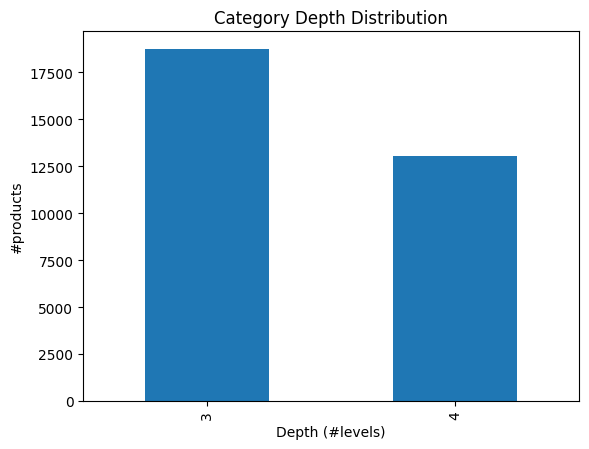

In [6]:
df["cat_depth"].value_counts().sort_index().plot(kind="bar")
plt.title("Category Depth Distribution")
plt.xlabel("Depth (#levels)")
plt.ylabel("#products")
plt.show()


Step 7 — Standardize all products to exactly 3 levels (L1, L2, L3)

In [7]:
def to_3_levels(path):
    if len(path) == 0:
        return (None, None, None)
    if len(path) == 1:
        return (path[0], path[0], path[0])
    if len(path) == 2:
        return (path[0], path[1], path[1])
    return (path[0], path[1], path[-1])

df[["L1","L2","L3"]] = df["cat_path"].apply(lambda p: pd.Series(to_3_levels(p)))

df["std_category_3lvl"] = df["L1"].fillna("") + " > " + df["L2"].fillna("") + " > " + df["L3"].fillna("")
df[["pathlist_names","std_category_3lvl"]].head(10)


,pathlist_names,std_category_3lvl
0,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
1,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
2,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
3,Computers & Electronics>Warranty & Support>War...,Computers & Electronics > Warranty & Support >...
4,Computers & Electronics>Computers>Notebooks,Computers & Electronics > Computers > Notebooks
5,Computers & Electronics>Computer Components>Sy...,Computers & Electronics > Computer Components ...
6,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
7,Computers & Electronics>Computer Cables>USB Ca...,Computers & Electronics > Computer Cables > US...
8,Computers & Electronics>Telecom & Navigation>S...,Computers & Electronics > Telecom & Navigation...
9,Computers & Electronics>Projectors>Projector A...,Computers & Electronics > Projectors > Project...


Step 8 — Product distribution per Level-3 category + min/max

In [8]:
cat_counts = df["std_category_3lvl"].value_counts()

print("Unique L3 categories:", cat_counts.size)
print("Min products in a category:", cat_counts.min())
print("Max products in a category:", cat_counts.max())

cat_counts.head(10)


Unique L3 categories: 353
Min products in a category: 1
Max products in a category: 6072


,count
std_category_3lvl,
Computers & Electronics > Computers > Notebook Spare Parts,6072
Computers & Electronics > Computers > Notebooks,5442
Computers & Electronics > Warranty & Support > Warranty & Support Extensions,1814
Computers & Electronics > Software > Software Licenses/Upgrades,1437
Computers & Electronics > Computers > PCs/Workstations,1425
Computers & Electronics > Printers & Scanners > Toner Cartridges,713
Computers & Electronics > Data Storage > Internal Hard Drives,531
Computers & Electronics > TVs & Monitors > TVs,530
Computers & Electronics > Data Input Devices > Keyboards,488


Step 9 — Plot category imbalance (histogram)

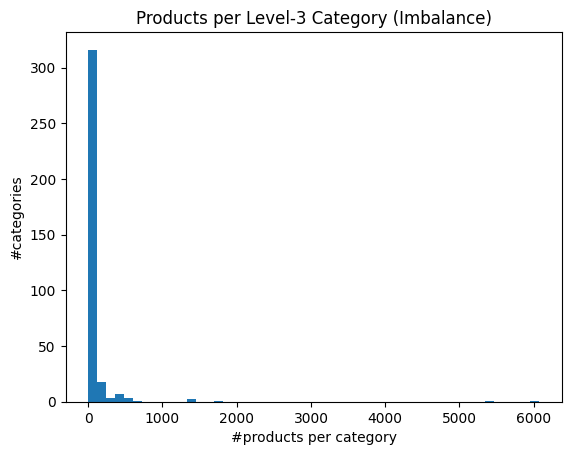

In [9]:
plt.hist(cat_counts.values, bins=50)
plt.title("Products per Level-3 Category (Imbalance)")
plt.xlabel("#products per category")
plt.ylabel("#categories")
plt.show()


Step 10 — Remove very small categories (NO padding)

In [10]:
MIN_PRODUCTS = 50

valid_cats = cat_counts[cat_counts >= MIN_PRODUCTS].index
df_bal = df[df["std_category_3lvl"].isin(valid_cats)].copy()

print("Original products:", len(df))
print("After removing small categories:", len(df_bal))
print("Remaining categories:", df_bal["std_category_3lvl"].nunique())


Original products: 31766
After removing small categories: 28560
Remaining categories: 73


Step 11 — Create text field (Brand + PartCode only)

In [11]:
df_bal["text"] = (
    df_bal["BrandInfo.BrandName"].fillna("") + " " +
    df_bal["BrandPartCode"].fillna("")
).str.strip()

df_ml = df_bal[df_bal["text"].str.len() > 5].copy()

print("Rows used for ML:", len(df_ml))
df_ml[["ID","text","std_category_3lvl"]].head(10)


Rows used for ML: 28560


,ID,text,std_category_3lvl
0,416603,DELL U8947,Computers & Electronics > Batteries & Power Su...
1,908983,Acer 60.A46V1.009,Computers & Electronics > Computers > Notebook...
2,955069,Toshiba SIC1016062LCD0,Computers & Electronics > Computers > Notebook...
3,494327,Fujitsu FSP:GB5H00Z00GBDPH,Computers & Electronics > Warranty & Support >...
4,691783,Lenovo 20BSS0EJ06,Computers & Electronics > Computers > Notebooks
5,430606,Lenovo 90007064,Computers & Electronics > Computer Components ...
6,381113,2-Power ALT28752A,Computers & Electronics > Batteries & Power Su...
7,555934,Eminent SB3017,Computers & Electronics > Computer Cables > US...
8,72913,Motorola PA700032ES,Computers & Electronics > Telecom & Navigation...
10,674497,Lenovo 80ML006AUK,Computers & Electronics > Computers > Notebooks


EMBEDDINGS + CLUSTERING (Step 12 — SBERT embeddings)

In [12]:
model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings_sbert = model.encode(
    df_ml["text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

embeddings_sbert = np.asarray(embeddings_sbert, dtype=np.float32)
print("SBERT embeddings shape:", embeddings_sbert.shape)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/447 [00:00<?, ?it/s]

SBERT embeddings shape: (28560, 384)


Step 13 — Hierarchical (Agglomerative) clustering on SBERT

In [13]:
N_CLUSTERS = 50

hac = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    metric="cosine",      # if error, use affinity="cosine"
    linkage="average"
)

df_ml["cluster_sbert"] = hac.fit_predict(embeddings_sbert)
df_ml["cluster_sbert"].value_counts().head(10)


,count
cluster_sbert,
4,21925
0,2769
23,830
11,719
25,319
46,278
45,234
3,208
33,160


Step 14 — Auto-label clusters using TF-IDF keywords

In [14]:
def label_clusters(texts, labels, top_n=5):
    vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
    X = vectorizer.fit_transform(texts)
    terms = np.array(vectorizer.get_feature_names_out())

    names = {}
    for c in sorted(set(labels)):
        idx = np.where(labels == c)[0]
        scores = X[idx].mean(axis=0).A1
        top_terms = terms[scores.argsort()[-top_n:]][::-1]
        names[c] = ", ".join(top_terms)
    return names

names_sbert = label_clusters(df_ml["text"].tolist(), df_ml["cluster_sbert"].values, top_n=5)
df_ml["auto_category_sbert"] = df_ml["cluster_sbert"].map(names_sbert)

df_ml[["text","cluster_sbert","auto_category_sbert"]].head(10)


,text,cluster_sbert,auto_category_sbert
0,DELL U8947,4,"hp, lenovo, toshiba, asus, acer"
1,Acer 60.A46V1.009,4,"hp, lenovo, toshiba, asus, acer"
2,Toshiba SIC1016062LCD0,4,"hp, lenovo, toshiba, asus, acer"
3,Fujitsu FSP:GB5H00Z00GBDPH,4,"hp, lenovo, toshiba, asus, acer"
4,Lenovo 20BSS0EJ06,4,"hp, lenovo, toshiba, asus, acer"
5,Lenovo 90007064,4,"hp, lenovo, toshiba, asus, acer"
6,2-Power ALT28752A,4,"hp, lenovo, toshiba, asus, acer"
7,Eminent SB3017,46,"apc, emc, aoc, eminent, px"
8,Motorola PA700032ES,4,"hp, lenovo, toshiba, asus, acer"
10,Lenovo 80ML006AUK,4,"hp, lenovo, toshiba, asus, acer"


Step 15 — Final percentage score: Weighted Purity (%)

In [15]:
sizes = df_ml["cluster_sbert"].value_counts()
dom = df_ml.groupby("cluster_sbert")["std_category_3lvl"].apply(lambda x: x.value_counts().iloc[0])

purity_weighted_sbert = (dom.sum() / sizes.sum()) * 100

print("SBERT clusters:", df_ml["cluster_sbert"].nunique())
print(f"SBERT Weighted Purity (%): {purity_weighted_sbert:.2f}%")


SBERT clusters: 50
SBERT Weighted Purity (%): 28.00%


Step 16 — Product-inside-cluster check

In [16]:
cluster_id = 0  # change this and rerun for different clusters
df_ml[df_ml["cluster_sbert"] == cluster_id][["text","std_category_3lvl","auto_category_sbert"]].head(25)


,text,std_category_3lvl,auto_category_sbert
14,Xerox 097S04588,Computers & Electronics > Printers & Scanners ...,"c2g, xerox, targus, kyocera, lite"
21,Duracell 150213932,Computers & Electronics > Batteries & Power Su...,"c2g, xerox, targus, kyocera, lite"
28,3M 98044050528,Computers & Electronics > TVs & Monitors > Dis...,"c2g, xerox, targus, kyocera, lite"
36,Zyxel ZY-ICUSG200ZAV2,Computers & Electronics > Software > Software ...,"c2g, xerox, targus, kyocera, lite"
37,C2G 16151,Computers & Electronics > Computer Components ...,"c2g, xerox, targus, kyocera, lite"
48,SilverHT 93016,Computers & Electronics > Computer Cables > Ca...,"c2g, xerox, targus, kyocera, lite"
52,Eaton T982A1-F-SS-015,Computers & Electronics > Batteries & Power Su...,"c2g, xerox, targus, kyocera, lite"
65,Iomega 34708,Computers & Electronics > Data Storage > Exter...,"c2g, xerox, targus, kyocera, lite"
68,Xerox C9000V_DT,Computers & Electronics > Printers & Scanners ...,"c2g, xerox, targus, kyocera, lite"
106,Hannspree HE245DPB,Computers & Electronics > TVs & Monitors > Com...,"c2g, xerox, targus, kyocera, lite"


EMBEDDING COMPARISON (SBERT vs TF-IDF baseline)
Step 17 — TF-IDF embeddings + HAC clustering

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering
import numpy as np

tfidf = TfidfVectorizer(stop_words="english", max_features=5000)
X_tfidf = tfidf.fit_transform(df_ml["text"].astype(str).tolist())

# find rows that are NOT all-zero
nonzero_mask = X_tfidf.getnnz(axis=1) > 0

print("Total rows:", X_tfidf.shape[0])
print("Zero-vector rows removed:", (~nonzero_mask).sum())
print("Rows kept for TF-IDF clustering:", nonzero_mask.sum())

# cluster only non-zero rows
X_tfidf_nz = X_tfidf[nonzero_mask]

hac2 = AgglomerativeClustering(
    n_clusters=N_CLUSTERS,
    metric="cosine",      # if your sklearn complains, use affinity="cosine"
    linkage="average"
)

labels_tfidf = hac2.fit_predict(X_tfidf_nz.toarray())

# store results back into df_ml
df_ml["cluster_tfidf"] = -1   # mark removed/empty rows as -1
df_ml.loc[nonzero_mask, "cluster_tfidf"] = labels_tfidf

df_ml["cluster_tfidf"].value_counts().head(10)


Total rows: 28560
Zero-vector rows removed: 12
Rows kept for TF-IDF clustering: 28548


Step 18 (Purity score)